# 7.1 · 实盘交易系统架构

> 回测是"离线模拟"，实盘是"真金白银、实时运行"。实盘系统要处理实时行情、信号、下单、成交、风控、监控、容灾，是一套完整的**软件工程**。
> 本节理解实盘交易系统的整体架构和核心模块，建立从"策略想法"到"稳定运行"的工程认知。

## 一、实盘系统的核心模块

一个完整的量化交易系统通常包含：

| 模块 | 职责 |
|---|---|
| **行情模块** | 接收实时/准实时行情，清洗、分发 |
| **策略模块** | 用行情/数据计算信号、目标仓位 |
| **组合/风控模块** | 校验约束、风险限额、合规 |
| **订单管理（OMS）** | 目标仓位→订单，拆单、智能下单、跟踪 |
| **交易接口（网关）** | 对接券商/交易所，发单、收回报 |
| **账户/持仓模块** | 维护资金、持仓、成交、净值 |
| **监控/报警** | 监控系统状态、盈亏、风险，异常报警 |
| **存储/日志** | 行情、订单、成交、日志持久化 |
| **调度/运维** | 定时任务、进程管理、容灾 |

## 二、实盘系统架构图

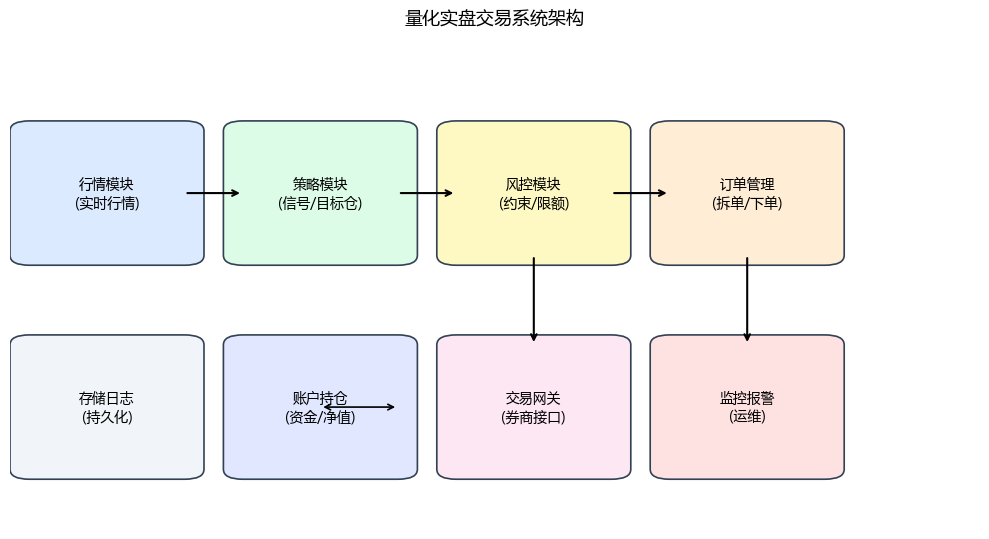

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mp
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 5.5)); ax.axis('off')

def box(x, y, w, h, text, color):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02',
                 fc=color, ec='#334155', lw=1.2))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=10)

box(0.02, 0.55, 0.16, 0.25, '行情模块\n(实时行情)', '#dbeafe')
box(0.24, 0.55, 0.16, 0.25, '策略模块\n(信号/目标仓)', '#dcfce7')
box(0.46, 0.55, 0.16, 0.25, '风控模块\n(约束/限额)', '#fef9c3')
box(0.68, 0.55, 0.16, 0.25, '订单管理\n(拆单/下单)', '#ffedd5')
box(0.46, 0.12, 0.16, 0.25, '交易网关\n(券商接口)', '#fce7f3')
box(0.24, 0.12, 0.16, 0.25, '账户持仓\n(资金/净值)', '#e0e7ff')
box(0.02, 0.12, 0.16, 0.25, '存储日志\n(持久化)', '#f1f5f9')
box(0.68, 0.12, 0.16, 0.25, '监控报警\n(运维)', '#fee2e2')
for x in [0.18, 0.40, 0.62]:
    ax.annotate('', xy=(x+0.06, 0.675), xytext=(x, 0.675),
                arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(0.76, 0.37), xytext=(0.76, 0.55),
            arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(0.54, 0.37), xytext=(0.54, 0.55),
            arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(0.40, 0.245), xytext=(0.32, 0.245),
            arrowprops=dict(arrowstyle='<->', lw=1.2))
ax.set_title('量化实盘交易系统架构', fontsize=13)
plt.tight_layout(); plt.show()

## 三、事件驱动：模块如何协作

实盘系统普遍采用**事件驱动（event-driven）**架构：
- 行情到达 → 产生"行情事件"；
- 策略监听行情 → 产生"信号事件"；
- 风控 → "订单事件"；
- 交易接口 → "成交回报事件"；
- 账户据此更新。

各模块通过事件解耦，易于扩展和维护。代码在 live_lab.engine。

In [2]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab.engine import EventEngine, Event
log = []
ee = EventEngine()
ee.register('MARKET', lambda e: log.append('行情: %s' % e.data))
ee.register('SIGNAL', lambda e: log.append('信号: %s' % e.data))
ee.register('ORDER', lambda e: log.append('订单: %s' % e.data))
for ev in [Event('MARKET', '09:30'), Event('SIGNAL', '买入A'), Event('ORDER', 'A')]:
    ee.send(ev)
ee.run()
for x in log: print(x)

行情: 09:30
信号: 买入A
订单: A


## 四、纸面交易：实盘前的必经一步

**Paper trading（模拟盘）**：用实时行情、真实系统流程，但不接真钱，模拟下单和成交。
- 验证系统是否正确（下单、回报、持仓、风控）；
- 验证策略在实时环境的表现，与回测对照；
- 发现回测中没暴露的问题（延迟、数据缺失、逻辑bug）。

> 上线顺序：**回测 → 模拟盘 → 小资金实盘 → 逐步加资金**。

代码在 live_lab.paper。

In [3]:
from live_lab.paper import PaperBroker
broker = PaperBroker(cash=1_000_000, cost_bps=10)
prices = {'A': 10.0, 'B': 20.0, 'C': 50.0}
broker.rebalance({'A': 0.4, 'B': 0.3, 'C': 0.3}, prices)
print('建仓后净值: %.2f（扣成本）' % broker.net_value(prices))
prices2 = {'A': 10.5, 'B': 19.5, 'C': 52.0}
print('行情变化后净值: %.2f' % broker.net_value(prices2))

建仓后净值: 999000.00（扣成本）
行情变化后净值: 1023500.00


## 五、回测到实盘的差异（务必重视）

| 维度 | 回测 | 实盘 |
|---|---|---|
| 数据 | 历史、完整 | 实时、可能缺失/错误 |
| 成交 | 假设成交、理想价 | 有延迟、滑点、可能不成交 |
| 涨跌停/停牌 | 易忽略 | 无法成交 |
| 成本 | 粗略估计 | 真实、可能更高 |
| 运行 | 一次性 | 7×? 长期稳定、需容灾 |
| 心态 | 无 | 真金白银的压力 |

> 实盘收益通常低于回测，差距主要来自**执行（滑点/未成交）和系统问题**。这就是为什么要模拟盘、小资金起步。

## 六、小结与面试要点

- 实盘系统：行情、策略、风控、OMS、交易网关、账户、监控、存储、运维。
- 事件驱动架构让模块解耦协作；纸面交易是实盘前必经验证。
- 上线顺序：回测→模拟盘→小资金→加资金；实盘差距主要在执行和系统。

**面试高频：**
- 一个完整的量化交易系统包含哪些模块？（答：行情、策略、风控、OMS、网关、账户、监控、存储）
- 为什么用事件驱动？（答：模块解耦、可扩展、符合实时交易流程）
- 策略上线前要做什么？（答：回测、模拟盘、小资金验证，逐步加资金）
- 回测和实盘为什么有差距？（答：滑点、延迟、未成交、数据问题、成本）

## 动手练习
1. 画出你自己的实盘系统模块图；
2. 用事件引擎串起"行情→信号→订单→成交"；
3. 列出你当前策略上实盘还缺哪些模块。

---
下一节 **7.2 订单管理：订单类型、智能下单（TWAP/VWAP）**。